<a id="top"></a>
# Autonomous Taxi Pickup and Drop-off: Comparative Analysis of SARSA, DQN, PPO, and SAC

**Course:** Reinforcement Learning Mini-Project  
**Author:** Sijan Pandey  
**Environment:** Gymnasium `Taxi-v4` ($5 \times 5$ Gridworld, $500$ Discrete States, $6$ Actions)  
**Algorithms Evaluated:** **SARSA** (On-Policy TD), **DQN** (Value-Based Off-Policy), **PPO** (On-Policy Actor-Critic), and **SAC** (Maximum-Entropy Off-Policy Actor-Critic)

---

### Project Overview
In this mini-project, we implement, evaluate, and compare four core Reinforcement Learning paradigms on the classic **Autonomous Taxi Pickup and Drop-off (`Taxi-v4`)** environment in Python using `gymnasium`:
1. **SARSA (State–Action–Reward–State–Action):** On-policy Temporal-Difference control using an $\varepsilon$-greedy behavior policy.
2. **DQN (Deep Q-Network):** Off-policy value-based learning using a parameterized Q-function, experience replay buffer, and target network updates.
3. **PPO (Proximal Policy Optimization):** On-policy Actor-Critic policy gradient method using a clipped surrogate objective and advantage estimation.
4. **SAC (Discrete Soft Actor-Critic):** Off-policy Actor-Critic method with **entropy regularization**, encouraging smooth exploration without uniform random penalties.

Beyond our four-algorithm comparison, we conduct **hyperparameter sensitivity experiments** on learning rate ($\alpha$), discount factor ($\gamma$), and exploration rate ($\varepsilon$), and visualize the learned state-value landscapes and step-by-step taxi delivery trajectories.

---

### Notebook Bookmarks (Table of Contents)
1. **[Section 1: Problem Formulation & Gymnasium `Taxi-v4` Environment Setup](#sec1)** — State space, action space, transition dynamics, and city grid visualization.
2. **[Section 2: On-Policy Temporal-Difference Control — SARSA](#sec2)** — Mathematical formulation, implementation, and baseline learning curves.
3. **[Section 3: Off-Policy Value Approximation — Deep Q-Network (DQN)](#sec3)** — Experience replay, target network bootstrapping, and training analysis.
4. **[Section 4: Clipped Policy Gradient — Proximal Policy Optimization (PPO)](#sec4)** — Actor-Critic architecture, clipped objective, and rollout performance.
5. **[Section 5: Maximum-Entropy RL — Discrete Soft Actor-Critic (SAC)](#sec5)** — Soft Bellman updates, entropy-regularized policy, and sample efficiency.
6. **[Section 6: Head-to-Head Algorithm Comparison (SARSA vs. DQN vs. PPO vs. SAC)](#sec6)** — Learning curves, convergence speed, return stability, and benchmark summary.
7. **[Section 7: Hyperparameter Sensitivity Analysis (α, γ, ε)](#sec7)** — Empirical effects of learning rate, discount factor, and exploration rate.
8. **[Section 8: Learned Policy Heatmaps & Optimal Taxi Delivery Trajectory](#sec8)** — Visualizing state values $V^*(s)$ and step-by-step pickup/drop-off routing.
9. **[Section 9: Key Findings & Conclusion](#sec9)** — Summary of which algorithm worked best and why.

---
<a id="sec1"></a>
## 1. Problem Formulation & Gymnasium `Taxi-v4` Environment Setup

**[Back to Top](#top)**

### 1.1 Markov Decision Process (MDP) Specification
The `Taxi-v4` environment (originally introduced by Dietterich, 2000 and featured in Sutton & Barto) models an autonomous taxi navigating a $5 \times 5$ gridworld with four designated pickup/drop-off terminals:
* **R (Red):** $(0, 0)$
* **G (Green):** $(0, 4)$
* **Y (Yellow):** $(4, 0)$
* **B (Blue):** $(4, 3)$

* **State Space ($|\mathcal{S}| = 500$):** Each state $s \in \{0, \dots, 499\}$ encodes a 4-tuple $(\text{taxi\_row}, \text{taxi\_col}, \text{pass\_loc}, \text{dest\_idx})$, where `pass_loc` $\in \{0,1,2,3\}$ indicates the passenger's waiting station or $4$ when inside the taxi.
* **Action Space ($|\mathcal{A}| = 6$):**
  * `0`: Move South ($\downarrow$)
  * `1`: Move North ($\uparrow$)
  * `2`: Move East ($\rightarrow$)
  * `3`: Move West ($\leftarrow$)
  * `4`: Pickup passenger (`P`)
  * `5`: Dropoff passenger (`D`)
* **Reward Structure ($R$):**
  * **$-1$ per step** for all movement and valid pickup actions (encourages shortest-path routing).
  * **$+20$** for successfully dropping the passenger off at the correct destination (terminal state).
  * **$-10$** for executing an illegal `Pickup` or `Dropoff` action.

In [1]:
# Section 1: Imports, Environment Initialization & Visual Inspection of Gymnasium Taxi-v4
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import gymnasium as gym

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F8FAFC',
    'axes.edgecolor': '#CBD5E1',
    'axes.grid': True,
    'grid.color': '#E2E8F0',
    'grid.linestyle': '--',
    'grid.alpha': 0.8,
    'font.size': 11,
    'axes.titlesize': 12.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5
})

# Initialize standard Gymnasium Taxi-v4 environment
env = gym.make("Taxi-v4")
n_states = env.observation_space.n
n_actions = env.action_space.n

# Fast lookup table from Gymnasium's unwrapped transition dictionary P[s][a]
P_table = env.unwrapped.P

def decode_taxi_state(s):
    """Decode integer state s in [0, 499] into (row, col, pass_loc, dest_idx)."""
    dest_idx = s % 4
    s //= 4
    pass_loc = s % 5
    s //= 5
    col = s % 5
    row = s // 5
    return row, col, pass_loc, dest_idx

def encode_taxi_state(row, col, pass_loc, dest_idx):
    """Encode (row, col, pass_loc, dest_idx) into integer state in [0, 499]."""
    return ((row * 5 + col) * 5 + pass_loc) * 4 + dest_idx

def rolling_mean(arr, window=50):
    return pd.Series(arr).rolling(window=window, min_periods=1).mean().values

print(f"Gymnasium Environment : Taxi-v4")
print(f"Observation Space     : Discrete({n_states})")
print(f"Action Space          : Discrete({n_actions}) -> [South(0), North(1), East(2), West(3), Pickup(4), Dropoff(5)]")

Gymnasium Environment : Taxi-v4
Observation Space     : Discrete(500)
Action Space          : Discrete(6) -> [South(0), North(1), East(2), West(3), Pickup(4), Dropoff(5)]


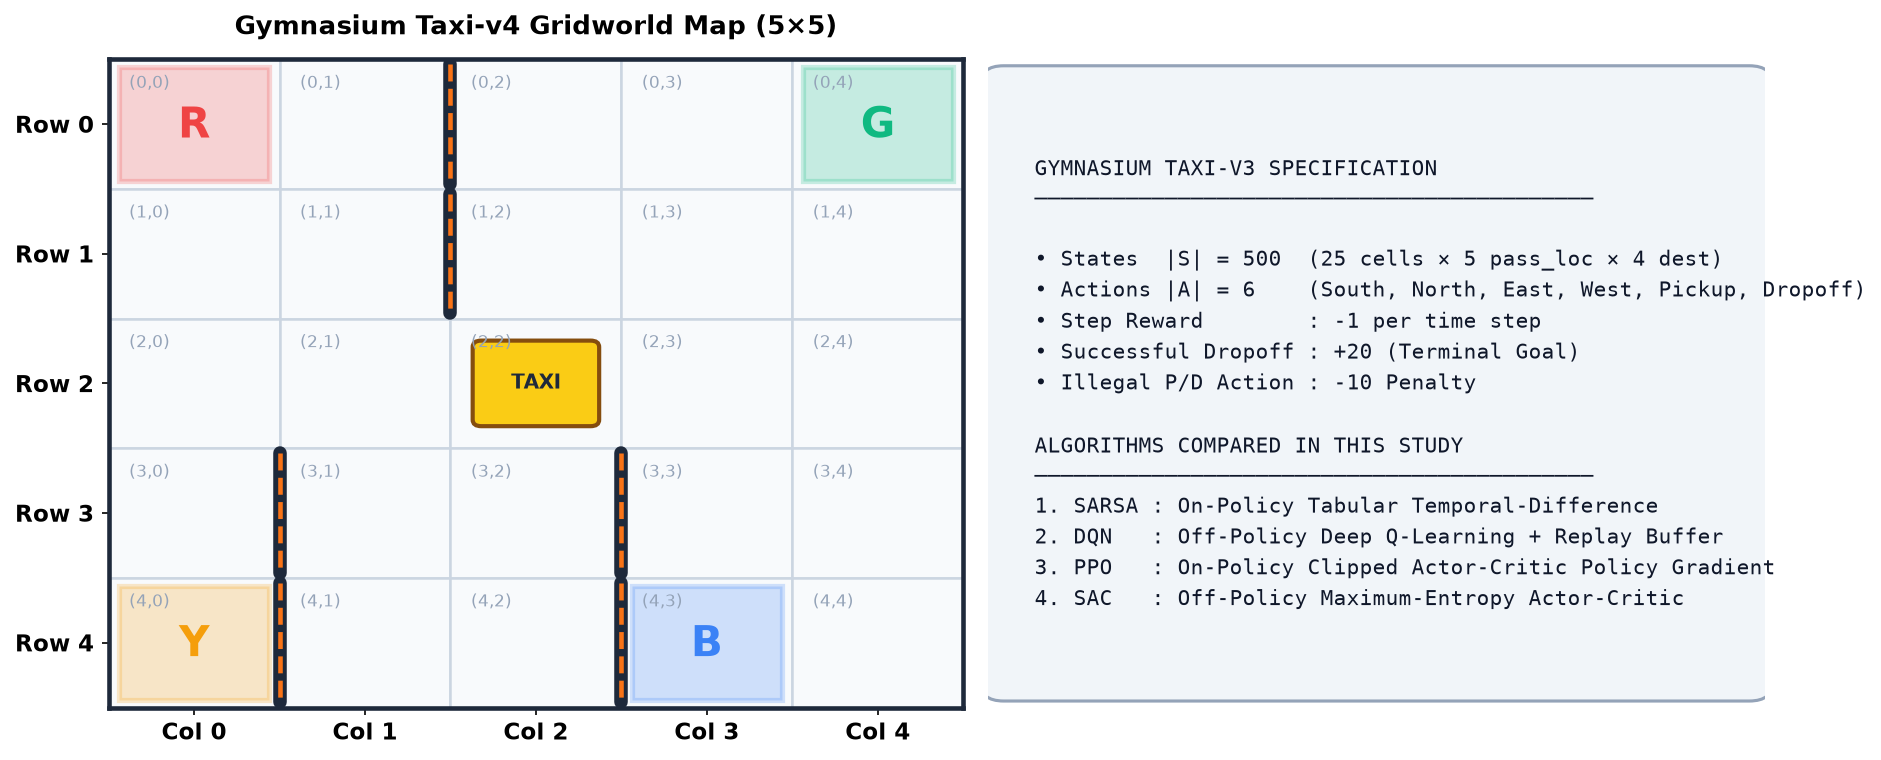

In [2]:
# Section 1.2: Visualize the Gymnasium Taxi-v4 Grid Layout & MDP Dynamics
def plot_taxi_v3_layout():
    stations = {0: (0, 0), 1: (0, 4), 2: (4, 0), 3: (4, 3)}
    station_colors = {0: '#EF4444', 1: '#10B981', 2: '#F59E0B', 3: '#3B82F6'}
    station_labels = {0: 'R', 1: 'G', 2: 'Y', 3: 'B'}
    walls_east = {(0, 1), (1, 1), (3, 0), (4, 0), (3, 2), (4, 2)}

    fig, (ax_map, ax_info) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.1, 1]})
    
    ax_map.set_xlim(0, 5)
    ax_map.set_ylim(0, 5)
    ax_map.invert_yaxis()
    ax_map.set_xticks(np.arange(0.5, 5.5, 1.0))
    ax_map.set_xticklabels([f"Col {c}" for c in range(5)], fontweight='bold')
    ax_map.set_yticks(np.arange(0.5, 5.5, 1.0))
    ax_map.set_yticklabels([f"Row {r}" for r in range(5)], fontweight='bold')
    ax_map.set_title("Gymnasium Taxi-v4 Gridworld Map (5×5)", pad=12)
    ax_map.grid(False)

    for r in range(5):
        for c in range(5):
            ax_map.add_patch(mpatches.Rectangle((c, r), 1, 1, facecolor='#F8FAFC', edgecolor='#CBD5E1', lw=1.2))
            ax_map.text(c + 0.12, r + 0.22, f"({r},{c})", fontsize=8, color='#94A3B8')

    for idx, (sr, sc) in stations.items():
        col = station_colors[idx]
        lbl = station_labels[idx]
        ax_map.add_patch(mpatches.Rectangle((sc+0.06, sr+0.06), 0.88, 0.88, facecolor=col, alpha=0.22, edgecolor=col, lw=2.5))
        ax_map.text(sc+0.5, sr+0.52, lbl, fontsize=20, fontweight='bold', color=col, ha='center', va='center')

    for (wr, wc) in walls_east:
        ax_map.plot([wc + 1, wc + 1], [wr + 0.04, wr + 0.96], color='#1E293B', lw=6.5, solid_capstyle='round')
        ax_map.plot([wc + 1, wc + 1], [wr + 0.04, wr + 0.96], color='#F97316', lw=2.2, linestyle='--')

    taxi_box = mpatches.FancyBboxPatch((2.18, 2.22), 0.64, 0.56, boxstyle="round,pad=0.05", facecolor='#FACC15', edgecolor='#854D0E', lw=2)
    ax_map.add_patch(taxi_box)
    ax_map.text(2.5, 2.5, "TAXI", fontsize=9.5, fontweight='bold', color='#1E293B', ha='center', va='center')

    for spine in ax_map.spines.values():
        spine.set_edgecolor('#1E293B')
        spine.set_linewidth(2.2)

    ax_info.axis('off')
    box = mpatches.FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle="round,pad=0.03", facecolor='#F1F5F9', edgecolor='#94A3B8', lw=1.5)
    ax_info.add_patch(box)
    txt = (
        "GYMNASIUM TAXI-V3 SPECIFICATION\n"
        "───────────────────────────────────────────\n\n"
        "• States  |S| = 500  (25 cells × 5 pass_loc × 4 dest)\n"
        "• Actions |A| = 6    (South, North, East, West, Pickup, Dropoff)\n"
        "• Step Reward        : -1 per time step\n"
        "• Successful Dropoff : +20 (Terminal Goal)\n"
        "• Illegal P/D Action : -10 Penalty\n\n"
        "ALGORITHMS COMPARED IN THIS STUDY\n"
        "───────────────────────────────────────────\n"
        "1. SARSA : On-Policy Tabular Temporal-Difference\n"
        "2. DQN   : Off-Policy Deep Q-Learning + Replay Buffer\n"
        "3. PPO   : On-Policy Clipped Actor-Critic Policy Gradient\n"
        "4. SAC   : Off-Policy Maximum-Entropy Actor-Critic"
    )
    ax_info.text(0.06, 0.50, txt, fontsize=10.2, family='monospace', color='#0F172A', va='center', linespacing=1.45)

    plt.tight_layout()
    fig.savefig(r"c:\Users\sijan\Desktop\rl_mini_project\figures\fig1_taxi_v3_layout.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_taxi_v3_layout()

---
<a id="sec2"></a>
## 2. Algorithm 1: On-Policy Temporal-Difference Control (SARSA)

**[Back to Top](#top)**

### 2.1 How SARSA Works
**SARSA** (Rummery & Niranjan, 1994; Sutton & Barto, Section 6.4) is an **on-policy** TD(0) algorithm. At each step, the agent experiences the 5-tuple $(S_t, A_t, R_{t+1}, S_{t+1}, A_{t+1})$ where both $A_t$ and $A_{t+1}$ are sampled from the current $\varepsilon$-greedy policy $\pi_\varepsilon$:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \Big[ R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \Big]$$

Because the update bootstrap target $Q(S_{t+1}, A_{t+1})$ uses the action actually taken in the next state, SARSA directly evaluates and improves the $\varepsilon$-greedy behavior policy, making it sensitive to exploratory penalties ($-10$ illegal actions) until $\varepsilon$ decays.

In [3]:
# Section 2: On-Policy SARSA Implementation & Training on Taxi-v4
def train_sarsa(episodes=2500, alpha=0.25, gamma=0.95, eps_start=1.0, eps_decay=0.996, eps_min=0.01, seed=42):
    rng = np.random.RandomState(seed)
    Q = np.zeros((n_states, n_actions), dtype=np.float64)
    epsilon = eps_start

    rewards_hist = np.zeros(episodes)
    steps_hist = np.zeros(episodes)
    illegal_hist = np.zeros(episodes)

    def select_action(s, eps):
        if rng.rand() < eps:
            return rng.randint(n_actions)
        q_row = Q[s]
        max_q = np.max(q_row)
        best = np.flatnonzero(np.isclose(q_row, max_q))
        return int(rng.choice(best))

    for ep in range(episodes):
        # Sample valid initial Taxi-v4 state
        s = rng.randint(n_states)
        r_c, c_c, p_c, d_c = decode_taxi_state(s)
        while p_c == 4 or p_c == d_c:
            s = rng.randint(n_states)
            r_c, c_c, p_c, d_c = decode_taxi_state(s)

        a = select_action(s, epsilon)
        ep_reward, ep_steps, ep_illegal = 0.0, 0, 0

        for _ in range(200):
            _, s_next, reward, terminated = P_table[s][a][0]
            a_next = select_action(s_next, epsilon)

            td_target = reward + (0.0 if terminated else gamma * Q[s_next, a_next])
            Q[s, a] += alpha * (td_target - Q[s, a])

            ep_reward += reward
            ep_steps += 1
            if reward == -10:
                ep_illegal += 1

            s, a = s_next, a_next
            if terminated:
                break

        rewards_hist[ep] = ep_reward
        steps_hist[ep] = ep_steps
        illegal_hist[ep] = ep_illegal
        epsilon = max(eps_min, epsilon * eps_decay)

    return Q, {"rewards": rewards_hist, "steps": steps_hist, "illegal": illegal_hist}

def evaluate_greedy_policy(policy_fn, n_eval=500, seed=999):
    rng = np.random.RandomState(seed)
    rews, stps, succ = [], [], []
    for _ in range(n_eval):
        s = rng.randint(n_states)
        r_c, c_c, p_c, d_c = decode_taxi_state(s)
        while p_c == 4 or p_c == d_c:
            s = rng.randint(n_states)
            r_c, c_c, p_c, d_c = decode_taxi_state(s)
        tot_r, steps = 0.0, 0
        for _ in range(200):
            a = int(policy_fn(s))
            _, s, r, term = P_table[s][a][0]
            tot_r += r
            steps += 1
            if term:
                succ.append(1)
                break
        else:
            succ.append(0)
        rews.append(tot_r)
        stps.append(steps)
    return np.mean(rews), np.std(rews), np.mean(stps), np.mean(succ) * 100.0

Q_sarsa, sarsa_hist = train_sarsa(episodes=2500)
sarsa_mean_r, sarsa_std_r, sarsa_steps, sarsa_succ = evaluate_greedy_policy(lambda s: np.argmax(Q_sarsa[s]))
print(f"[SARSA Evaluation] Greedy Return: {sarsa_mean_r:+.2f} ± {sarsa_std_r:.2f} | Mean Steps: {sarsa_steps:.2f} | Success Rate: {sarsa_succ:.1f}%")

[SARSA Evaluation] Greedy Return: +7.01 ± 3.03 | Mean Steps: 13.99 | Success Rate: 100.0%
